# 01_EDA.ipynb
Exploratory Data Analysis for RetailX

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
PROJECT_ROOT = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / 'data' / 'processed').exists())
DATA = PROJECT_ROOT / 'data' / 'processed' / 'cleaned_sales_data.csv'
df = pd.read_csv(DATA, parse_dates=['Order_Date','Ship_Date'])
df.head()


,Order_ID,Order_Date,Ship_Date,Sales_Channel,Payment_Mode,Order_Status,Return_Flag,Customer_ID,Customer_Name,Customer_Segment,...,Quantity,Discount,Sales,Profit,City,State,Region,Postal_Code,Calculated_Profit,Profit_Margin
0,O111767,2022-05-09,2022-05-11,Online,Cash,Shipped,0,C2262,Customer_1262,Consumer,...,2,0.8,2376.40,24.964,Chicago,IL,South,70846,24.964,0.010505
1,O100793,2020-03-02,2020-03-04,Online,Debit Card,Completed,0,C1063,Customer_63,Consumer,...,3,0.8,3046.00,47.244,New York,TX,East,22621,47.244,0.015510
2,O111279,2022-04-04,2022-04-09,Online,Credit Card,Completed,0,C1658,Customer_658,Consumer,...,1,0.8,1503.85,32.850,New York,CA,Midwest,85017,32.850,0.021844
3,O110578,2022-02-10,2022-02-12,Retail,Credit Card,Completed,0,C3609,Customer_2609,Consumer,...,1,0.8,952.45,24.506,Houston,IL,South,33590,24.506,0.025729
4,O117338,2023-06-10,2023-06-15,Retail,Debit Card,Completed,0,C1172,Customer_172,Consumer,...,2,0.8,1999.10,28.980,Chicago,TX,Midwest,35642,28.980,0.014497


## Business questions
This notebook answers: How do sales change over time? Which categories and regions drive revenue? How does discounting relate to profit? Where are unusual transactions?


In [2]:
df.info()
summary = pd.DataFrame({
    'metric': ['rows', 'orders', 'customers', 'revenue', 'profit', 'profit_margin'],
    'value': [len(df), df['Order_ID'].nunique(), df['Customer_ID'].nunique(), df['Sales'].sum(), df['Profit'].sum(), df['Profit'].sum() / df['Sales'].sum()]
})
summary


<class 'pandas.DataFrame'>
RangeIndex: 32181 entries, 0 to 32180
Data columns (total 28 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   Order_ID           32181 non-null  str           
 1   Order_Date         32181 non-null  datetime64[us]
 2   Ship_Date          32181 non-null  datetime64[us]
 3   Sales_Channel      32181 non-null  str           
 4   Payment_Mode       32181 non-null  str           
 5   Order_Status       32181 non-null  str           
 6   Return_Flag        32181 non-null  int64         
 7   Customer_ID        32181 non-null  str           
 8   Customer_Name      32181 non-null  str           
 9   Customer_Segment   32181 non-null  str           
 10  Customer_Age       32181 non-null  float64       
 11  Customer_Gender    32181 non-null  str           
 12  Product_ID         32181 non-null  str           
 13  Product_Name       32181 non-null  str           
 14  Category         

,metric,value
0,rows,3.218100e+04
1,orders,2.000000e+04
2,customers,2.999000e+03
3,revenue,1.120841e+07
4,profit,4.582262e+06
5,profit_margin,4.088237e-01


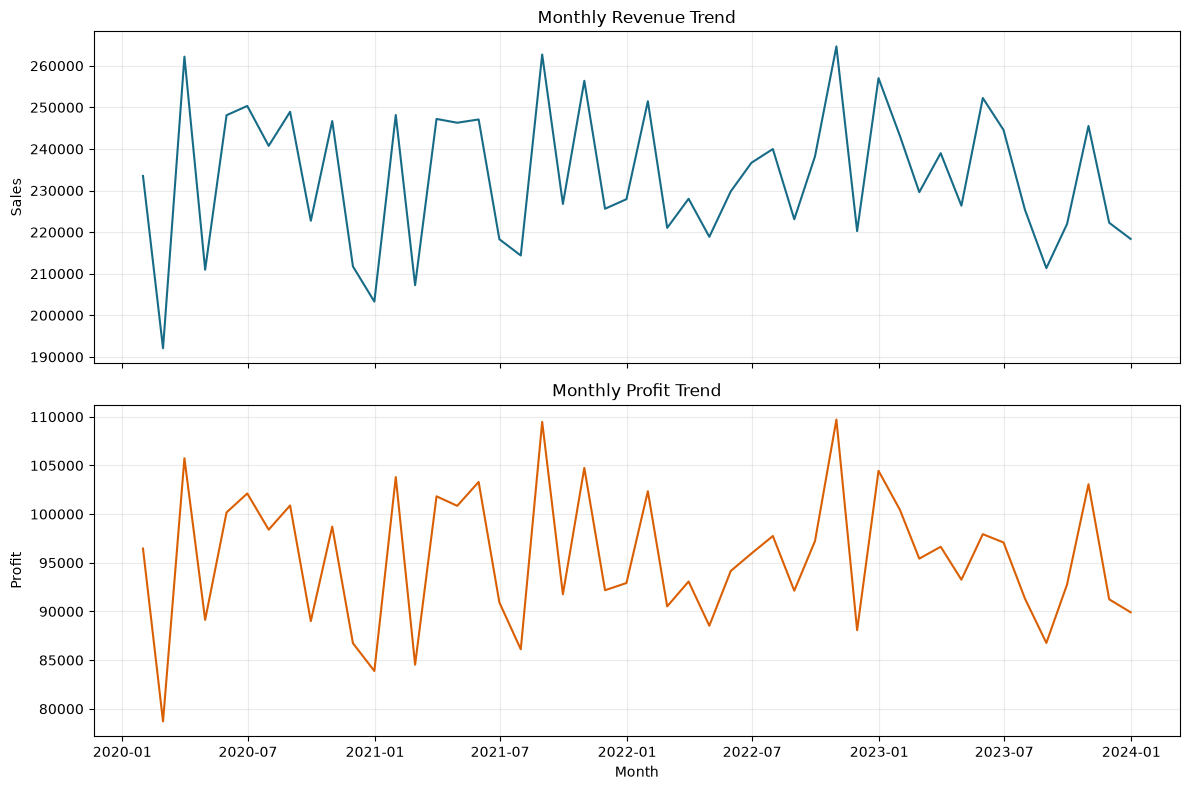

In [3]:
monthly = df.set_index('Order_Date').resample('ME').agg(Sales=('Sales', 'sum'), Profit=('Profit', 'sum')).reset_index()
fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
sns.lineplot(data=monthly, x='Order_Date', y='Sales', ax=axes[0], color='#176b87')
sns.lineplot(data=monthly, x='Order_Date', y='Profit', ax=axes[1], color='#d95f02')
axes[0].set_title('Monthly Revenue Trend')
axes[1].set_title('Monthly Profit Trend')
for ax in axes:
    ax.set_xlabel('Month')
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()


In [4]:
category = df.groupby('Category', as_index=False).agg(Sales=('Sales', 'sum'), Profit=('Profit', 'sum'))
category['Profit_Margin'] = category['Profit'] / category['Sales']
category.sort_values('Sales', ascending=False)


,Category,Sales,Profit,Profit_Margin
1,Electronics,3233250.74,1332716.070,0.412191
0,Clothing,2607396.32,1041722.002,0.399526
2,Furniture,2201773.10,919845.178,0.417775
3,Home & Kitchen,1803051.07,748672.418,0.415225
4,Office Supplies,1362936.01,539306.354,0.395695


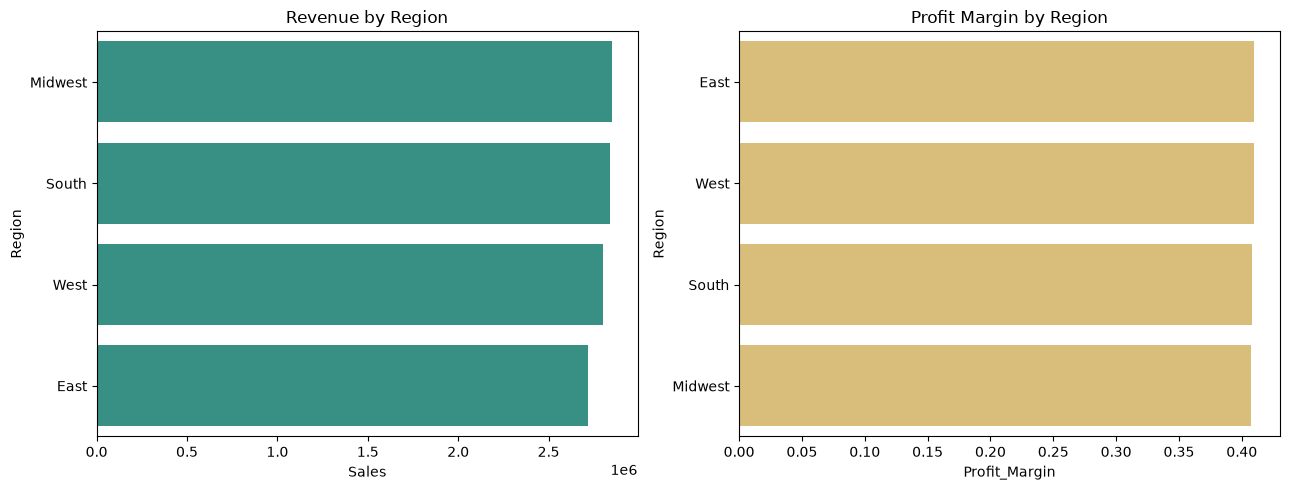

In [5]:
region = df.groupby('Region', as_index=False).agg(Sales=('Sales', 'sum'), Profit=('Profit', 'sum'))
region['Profit_Margin'] = region['Profit'] / region['Sales']
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(data=region.sort_values('Sales', ascending=False), x='Sales', y='Region', ax=axes[0], color='#2a9d8f')
sns.barplot(data=region.sort_values('Profit_Margin', ascending=False), x='Profit_Margin', y='Region', ax=axes[1], color='#e9c46a')
axes[0].set_title('Revenue by Region')
axes[1].set_title('Profit Margin by Region')
plt.tight_layout()
plt.show()
